In [18]:
from langchain_openai import ChatOpenAI

# 모델 초기화
model = ChatOpenAI(model="gpt-6-luna")
model.invoke('안녕하세요!')

AIMessage(content='안녕하세요! 무엇을 도와드릴까요? 😊', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 9, 'total_tokens': 24, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EXld92YLreg207PcXWrQiLBau8xZ0', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a12aa1-ffb3-70f3-ab37-4b68befecfcf-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 15, 'total_tokens': 24, 'input_token_details': {'audio': 0, 'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [19]:
from typing import Annotated # annotated는 타입 힌트를 사용할 때 사용하는 함수
from typing_extensions import TypedDict # TypedDict는 딕셔너리 타입을 정의할 때 사용하는 함수

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):
    """
    State 클래스는 TypedDict를 상속받습니다.

    속성:
        messages (Annotated[list[str], add_messages]): 메시지들은 "list" 타입을 가집니다. 
        주석에 있는 'add_messages' 함수는 이 상태 키가 어떻게 업데이트되어야 하는지를 정의합니다.
        (이 경우, 메시지를 덮어쓰는 대신 리스트에 추가합니다)
    """
    messages: Annotated[list[str], add_messages]

# StateGraph 클래스를 사용하여 State 타입의 그래프를 생성합니다.
graph_builder = StateGraph(State) 

In [ ]:
from langchain_core.tools import tool
from datetime import datetime
import pytz
from langchain_community.tools import DuckDuckGoSearchResults
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper

import bs4
from langchain_community.document_loaders import WebBaseLoader

# 도구 함수 정의
@tool
def get_current_time(timezone: str, location: str) -> str:
    """현재 시각을 반환하는 함수."""
    try:
        tz = pytz.timezone(timezone)
        now = datetime.now(tz).strftime("%Y-%m-%d %H:%M:%S")
        result = f'{timezone} ({location}) 현재시각 {now}'
        # print(result)
        return result
    except pytz.UnknownTimeZoneError:
        return f"알 수 없는 타임존: {timezone}"
    
@tool
def get_web_search(query: str, search_period: str='m') -> str:
    """
    웹 검색을 수행하는 함수.

    Args:
        query (str): 검색어
        search_period (str): 검색 기간 (e.g., "w" for past week (default), "m" for past month, "y" for past year, "d" for past day)

    Returns:
        str: 검색 결과
    """
    wrapper = DuckDuckGoSearchAPIWrapper(
        region="kr-kr", 
        time=search_period
    )

    print('\n-------- WEB SEARCH --------')
    print(query)
    print(search_period)

    search = DuckDuckGoSearchResults(
        api_wrapper=wrapper,
        backend="news",
        results_separator=';\n'
    )

    searched = search.invoke(query)
    
    for i, result in enumerate(searched.split(';\n')):
        print(f'{i+1}. {result}')
    
    return searched

# 도구 바인딩
tools = [get_current_time, get_web_search]

In [21]:
tools[0].invoke({"timezone": "Asia/Seoul", "location": "서울"})

'Asia/Seoul (서울) 현재시각 2026-10-11 20:03:44'

In [22]:
tools[1].invoke({"query": "파이썬", "search_period": "m"})


-------- WEB SEARCH --------
파이썬
m
1. snippet: 큐브로이드는 학생이 원하는 로봇 동작을 한국어 문장으로 입력하면 파이썬 코드가 생성되는 ‘아티보 바이브코딩’을 공개했다고 밝혔다. 교육용 AI 로봇 아티보(ARTIBO)의 파이썬 코딩 화면에 적용한 기능으로, 학생이 생성된 코드를 살펴보고 설명을 요청하거나 동작을 고칠 ..., title: 큐브로이드, 말로 아티보 코드를 만드는 ‘바이브코딩’ 공개, link: https://www.gosiweek.com/article/1065581076850137, date: 2026-10-08T11:03:44+00:00, source: 피앤피뉴스
2. snippet: [Daily U's Line 데일리 유스라인 디지털국] 경남대 SW중심대학사업단은 지난 9월 19일부터 20일까지 제1공학관 SW융합실습실에서 ‘2026학년도 2학기 PCCE(코딩필수역량인증) 자격증 특강반’을 운영했다., title: 경남대 SW중심대학사업단, PCCE 특강 참가자 27명 전원 합격, link: https://www.usline.kr/news/articleView.html?idxno=34901, date: 2026-09-29T11:03:44+00:00, source: 유스라인
3. snippet: KALS(Korea AI Leaders) 교육연구센터가 청소년 대상 AI 교육을 시작으로 대학, 공공기관, 기업 현장까지 활동 영역을 확대하고 있다고 밝혔다. KALS는 2026년 2월 분당·판교 지역에 설립된 교육연구센터로 ..., title: KALS, 청소년 AI 교육서 기업 AX까지 활동 확대…전 생애 AI 교육체계 구축 추진, link: https://www.kdpress.co.kr/news/articleView.html?idxno=209117, date: 2026-10-08T11:03:44+00:00, source: 데일리경제
4. snippet: 쉽고 단순하면 확장이 어렵고, 기능이 많으면 관리가 까다롭

"snippet: 큐브로이드는 학생이 원하는 로봇 동작을 한국어 문장으로 입력하면 파이썬 코드가 생성되는 ‘아티보 바이브코딩’을 공개했다고 밝혔다. 교육용 AI 로봇 아티보(ARTIBO)의 파이썬 코딩 화면에 적용한 기능으로, 학생이 생성된 코드를 살펴보고 설명을 요청하거나 동작을 고칠 ..., title: 큐브로이드, 말로 아티보 코드를 만드는 ‘바이브코딩’ 공개, link: https://www.gosiweek.com/article/1065581076850137, date: 2026-10-08T11:03:44+00:00, source: 피앤피뉴스;\nsnippet: [Daily U's Line 데일리 유스라인 디지털국] 경남대 SW중심대학사업단은 지난 9월 19일부터 20일까지 제1공학관 SW융합실습실에서 ‘2026학년도 2학기 PCCE(코딩필수역량인증) 자격증 특강반’을 운영했다., title: 경남대 SW중심대학사업단, PCCE 특강 참가자 27명 전원 합격, link: https://www.usline.kr/news/articleView.html?idxno=34901, date: 2026-09-29T11:03:44+00:00, source: 유스라인;\nsnippet: KALS(Korea AI Leaders) 교육연구센터가 청소년 대상 AI 교육을 시작으로 대학, 공공기관, 기업 현장까지 활동 영역을 확대하고 있다고 밝혔다. KALS는 2026년 2월 분당·판교 지역에 설립된 교육연구센터로 ..., title: KALS, 청소년 AI 교육서 기업 AX까지 활동 확대…전 생애 AI 교육체계 구축 추진, link: https://www.kdpress.co.kr/news/articleView.html?idxno=209117, date: 2026-10-08T11:03:44+00:00, source: 데일리경제;\nsnippet: 쉽고 단순하면 확장이 어렵고, 기능이 많으면 관리가 까다롭다는 점은 기존 로봇 교구의 오랜 한계였다. ‘단 한 종류의 모듈로 세상의

In [23]:
for tool in tools:
    print(tool.name, tool)

get_current_time name='get_current_time' description='현재 시각을 반환하는 함수.' args_schema=<class 'langchain_core.utils.pydantic.get_current_time'> func=<function get_current_time at 0x0000022A7CBE9EE0>
get_web_search name='get_web_search' description='웹 검색을 수행하는 함수.\n\nArgs:\n    query (str): 검색어\n    search_period (str): 검색 기간 (e.g., "w" for past week (default), "m" for past month, "y" for past year, "d" for past day)\n\nReturns:\n    str: 검색 결과' args_schema=<class 'langchain_core.utils.pydantic.get_web_search'> func=<function get_web_search at 0x0000022A7A96C900>


In [24]:
model_with_tools = model.bind_tools(tools) # GPT 언어모델에 도구 연결

def generate(state: State):
    """
    주어진 상태를 기반으로 챗봇의 응답 메시지를 생성합니다.

    매개변수:
    state (State): 현재 대화 상태를 나타내는 객체로, 이전 메시지들이 포함되어 있습니다.

    반환값:
    dict: 모델이 생성한 응답 메시지를 포함하는 딕셔너리. 
          형식은 {"messages": [응답 메시지]}입니다.
    """
    return {"messages": model_with_tools.invoke(state["messages"])}

graph_builder.add_node("generate", generate)

In [25]:
import json
from langchain_core.messages import ToolMessage

class BasicToolNode:
    """
    도구를 실행하는 노드 클래스입니다. 마지막 AIMessage에서 요청된 도구를 실행합니다.
    Attributes:
        tools_by_name (dict): 도구 이름을 키로 하고 도구 객체를 값으로 가지는 사전입니다.
    Methods:
        __init__(tools: list): 도구 객체들의 리스트를 받아서 초기화합니다.
        __call__(inputs: dict): 입력 메시지를 받아서 도구를 실행하고 결과 메시지를 반환합니다.
    """
    """A node that runs the tools requested in the last AIMessage."""

    def __init__(self, tools: list) -> None:    # ①
        self.tools_by_name = {tool.name: tool for tool in tools}

    def __call__(self, inputs: dict):    # ②
        if messages := inputs.get("messages", []):
            # inputs에 messages가 있으면 messages를 가져오고 없으면 빈 리스트를 가져옵니다.
            message = messages[-1]
        else:
            raise ValueError("No message found in input")
        outputs = []
        for tool_call in message.tool_calls:    # ③
            tool_result = self.tools_by_name[tool_call["name"]].invoke(
                tool_call["args"]
            )
            outputs.append(
                ToolMessage(
                    content=json.dumps(tool_result),
                    name=tool_call["name"],
                    tool_call_id=tool_call["id"],
                )
            )
        return {"messages": messages + outputs}

tool_node = BasicToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)

In [26]:
def route_tools(state: State):
    """
    마지막 메시지에 도구 호출이 있는 경우 ToolNode로 라우팅하고,
    그렇지 않은 경우 끝으로 라우팅하기 위해 conditional_edge에서 사용합니다.
    """
    if isinstance(state, list):
        ai_message = state[-1]
    elif messages := state.get("messages", []):
        ai_message = messages[-1]
    else:
        raise ValueError(f"tool_edge 입력 상태에서 메시지를 찾을 수 없습니다: {state}")
    if hasattr(ai_message, "tool_calls") and len(ai_message.tool_calls) > 0:
        return "tools"
    return END

graph_builder.add_edge(START, "generate")

graph_builder.add_conditional_edges(
    "generate",
    route_tools,
    {"tools": "tools", END: END},
)
# 도구가 호출될 때마다 다음 단계를 결정하기 위해 챗봇으로 돌아갑니다.
graph_builder.add_edge("tools", "generate")
graph = graph_builder.compile()

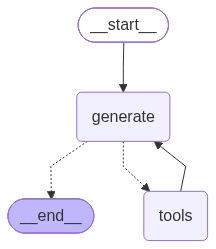

In [27]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [28]:
from langchain_core.messages import AIMessageChunk, HumanMessage

inputs = [HumanMessage(content="지금 서울 몇시야?")]

gathered = ""

for msg, metadata in graph.stream({"messages": inputs}, stream_mode="messages"):
    if isinstance(msg, AIMessageChunk):
        print(msg.text, end="")
        gathered += msg.text

gathered

서울은 지금 **2026년 10월 11일 오후 8시 3분**이에요.

'서울은 지금 **2026년 10월 11일 오후 8시 3분**이에요.'

In [31]:
from langchain_core.messages import AIMessageChunk, SystemMessage

about = "서울월드컵 경기장 잔디 문제"

inputs = [SystemMessage(content=f"""
너는 신문기자이다. 
최근 {about}에 대해 비판하는 심층 분석 기사를 쓰려고 한다.  

- 최근 어떤 이슈가 있는지 검색하고, 사람들이 제일 관심있어 할만한 주제를 선정하고, 왜 선정했는지 말해줘. 
- 그 내용으로 원고를 작성하기 위한 목차를 만들고, 목차 내용을 채우기 위해 추가로 검색할 내용을 리스트로 정리해봐. 
- 검색할 리스트를 토대로 재검색을 한다. 
- 목차에 있는 내용을 작성하기 위해 더 검색이 필요한 정보가 있는지 확인하고, 있다면 추가로 검색해라.
- 검색된 결과에 원하는 정보를 찾지 못했다면 다른 검색어로 재검색해도 좋다. 

더 이상 검색할 내용이 없다면, 조선일보 신문 기사 형식으로 최종 기사를 작성하라.
제목, 부제, 리드문, 본문 의 구성으로 작성하라. 본문 내용은 심층 분석 기사에 맞게 구체적이고 깊이 있게 작성해야 한다. 
    
""")]

for msg, metadata in graph.stream({"messages": inputs}, stream_mode="messages"):
    if isinstance(msg, AIMessageChunk):
        print(msg.content, end='')

[][{'id': 'rs_0ca1bc6344b8896a006acb6de6431487d0a3f568e028e30d4f', 'summary': [], 'type': 'reasoning', 'content': [], 'index': 0}][{'type': 'reasoning', 'id': 'rs_0ca1bc6344b8896a006acb6de6431487d0a3f568e028e30d4f', 'summary': [], 'encrypted_content': 'gAAAAABqy23mb3j0GEGAkvMZyqNzPUbVVfUFWLP3KyoXC5UU8T5XcNklnPnkpMIxMqTfV2t-P0eUe5HPsUW2MMZXgWEllHYRVQbp34RUBIeEAhnYLVdpIdqH4iB1DbzwhbeJ0OuJY1UrmNElMQQUHXlRBQs23i5KWkjL3TzYrmb6nG9dZbidlvnehV8sgFg6i26tbubcZU4XgIzNFMbW7ZodR4SCUIm7RKAEVqfaUZvHMvaqJoD-CV8uvE8Eux6hIrdJnygy4Iu4EzMnRZ-273hEMzKsr5k_h0uIFMDbOhDHQPp5Yq8yiA6zaQdj2zcu4Kho2phFc-qaSJKjUi3g3zx90uak-9RYOmFzY9AiCcw0MAZvfUuUWBrNvbMQ1vijwnk2ZiVVzjuQwq-P0Xtx-SXVXe3i-Twb0SZVTRBOzEG36csJpqzT7Ada1k55sjUq7ludbhIvdjuL_G0XU42Ged3zRfWrzMpMrAOsUI-MKS8suPnYyuemirAyftMGOpAZrapqzZp9dnZ2w16g2jjqu2Tih0z1dec3wYrujx42mtMWsMYF_Nmr-3iZt8F0kuQe6PoqNbKDcTdY3T4rMwmxRfV2poJthrs4qEeuXkQCmfSyMTjUYQxAt7_kyNOOUKSQOFbig_VzANNzs8rt27ac2Phbe4Tcl8UUb_3A2HZzFc9iKPpyLajztlQ8hQLYCbd1Guaj0s9G-lXn4DMWzoAbmJc759B3R7qO9p9ZoyqF-TH

DDGSException: No results found.